Auto ARIMA on monthly-beer-production-in-austr dataset
-
Auto-(S)ARIMA(X) forecaster, from pmdarima package.

Includes automated fitting of (S)ARIMA(X) hyper-parameters (p, d, q, P, D, Q)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sktime.forecasting.compose import make_reduction
from sktime.forecasting.model_selection import temporal_train_test_split
from sktime.performance_metrics.forecasting import MeanSquaredError
from sktime.utils.plotting import plot_series
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sktime.forecasting.arima import AutoARIMA
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

In [15]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
# Also common in time series to ignore UserWarnings about frequency
warnings.filterwarnings("ignore", category=UserWarning)

In [16]:
df = pd.read_csv("monthly-beer-production-in-austr.csv", index_col=0)
df

,Monthly beer production
Month,
1956-01,93.2
1956-02,96.0
1956-03,95.2
1956-04,77.1
1956-05,70.9
...,...
1995-04,127.0
1995-05,151.0
1995-06,130.0


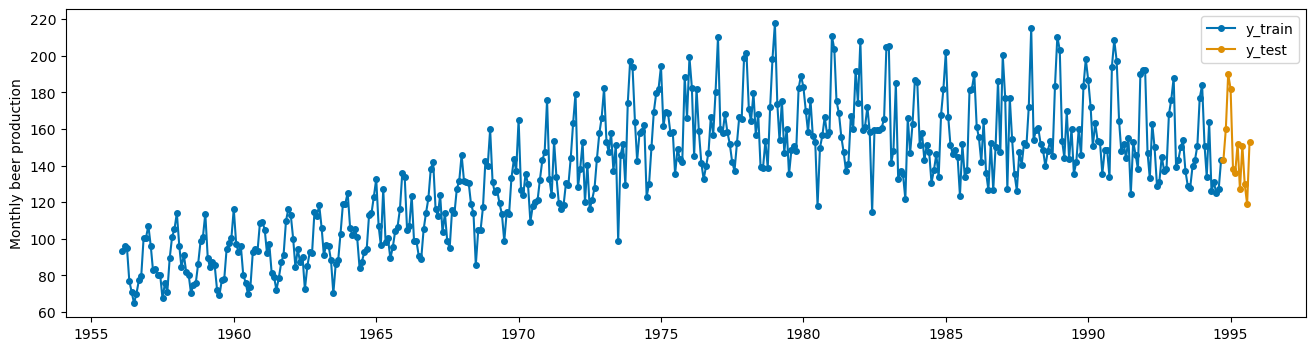

In [17]:
df.index = pd.date_range(start = '1956-01-01',periods = len(df),freq = 'ME') # time indexing must for sktime & ME (month end)
y =df['Monthly beer production']
y_train,y_test = temporal_train_test_split(y,test_size=12)
plot_series(y_train,y_test,labels=["y_train","y_test"])
plt.legend()
plt.show()

In [18]:
forecaster= AutoARIMA(sp =12,d=0,max_p=3,max_q=3,max_P=3,max_D=1,max_Q=3,suppress_warnings=True,trace=True)
forecaster.fit(y_train)

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[12] intercept   : AIC=3624.375, Time=1.85 sec
 ARIMA(0,0,0)(0,0,0)[12] intercept   : AIC=4591.107, Time=0.03 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : AIC=inf, Time=0.86 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : AIC=4066.397, Time=0.44 sec
 ARIMA(0,0,0)(0,0,0)[12]             : AIC=5906.266, Time=0.02 sec
 ARIMA(2,0,2)(0,0,1)[12] intercept   : AIC=3835.248, Time=1.66 sec
 ARIMA(2,0,2)(1,0,0)[12] intercept   : AIC=inf, Time=1.48 sec
 ARIMA(2,0,2)(2,0,1)[12] intercept   : AIC=3648.822, Time=3.53 sec
 ARIMA(2,0,2)(1,0,2)[12] intercept   : AIC=3650.685, Time=3.58 sec
 ARIMA(2,0,2)(0,0,0)[12] intercept   : AIC=4018.867, Time=0.37 sec
 ARIMA(2,0,2)(0,0,2)[12] intercept   : AIC=3739.730, Time=3.14 sec
 ARIMA(2,0,2)(2,0,0)[12] intercept   : AIC=3627.222, Time=3.16 sec
 ARIMA(2,0,2)(2,0,2)[12] intercept   : AIC=inf, Time=4.40 sec
 ARIMA(1,0,2)(1,0,1)[12] intercept   : AIC=inf, Time=1.45 sec
 ARIMA(2,0,1)(1,0,1)[12] intercept   : 

AutoARIMA(d=0, max_P=3, max_Q=3, max_p=3, max_q=3, sp=12,
          suppress_warnings=True, trace=True)

c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)
c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)
c:\Users\dbda.STUDENTSDC

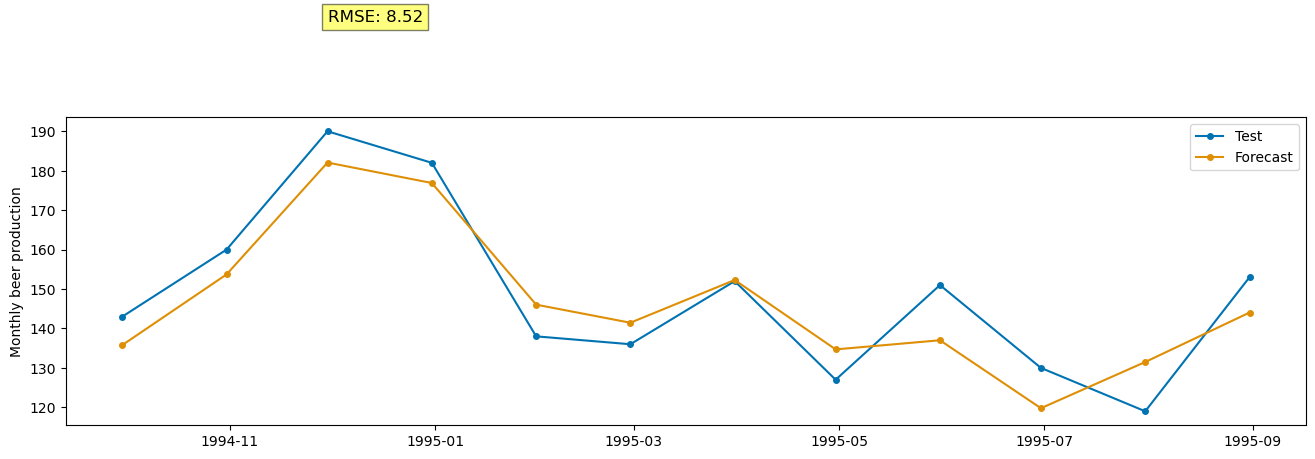

In [19]:
y_pred = forecaster.predict(fh=np.arange(1,len(y_test)+1))
rmse = MeanSquaredError(square_root=True)
plot_series(y_test,y_pred,labels=["Test","Forecast"])
plt.text(y.index[-10],max(y),f'RMSE: {rmse(y_test,y_pred):.2f}',fontsize =12,bbox=dict(facecolor='yellow', alpha=0.5))
plt.legend()
plt.show()

Random Forest Regressor & Grid Search
-

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sktime.forecasting.model_selection import ForecastingGridSearchCV, SlidingWindowSplitter

regressor = RandomForestRegressor(random_state=25)
forecaster = make_reduction(regressor,strategy="recursive")
param_grid = {'window_length': [7,8,10,12,15],
              'estimator__max_features':['sqrt','log2']}
cv = SlidingWindowSplitter(initial_window=int(len(y_train)*0.8),window_length=20)
gscv = ForecastingGridSearchCV(forecaster, strategy="refit", cv=cv, scoring=rmse,param_grid=param_grid)
gscv.fit(y_train)
print(gscv.best_params_)
print(gscv.best_score_)

{'estimator__max_features': 'log2', 'window_length': 8}
14.488118279569894
